<a href="https://colab.research.google.com/github/koji/AI-Colab-Notebooks/blob/main/liquid_ai_d1_3B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q "transformers==5.19.0" pillow soundfile pyarrow scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 58.0 MB/s eta 0:00:00


In [2]:
import json, time, platform, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torchvision
import soundfile as sf
from PIL import Image
from IPython.display import display, Audio
from google.colab import files

assert torch.cuda.is_available(), "Select T4 in Runtime"

DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name(0))
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Transformers:", importlib.metadata.version("transformers"))

ASSETS = Path("/content/d1_demo/assets")
(ASSETS / "images").mkdir(parents=True, exist_ok=True)
(ASSETS / "audio").mkdir(parents=True, exist_ok=True)

GPU: Tesla T4
Python: 3.13.15
PyTorch: 2.11.0+cu130
Transformers: 5.19.0


In [7]:
from transformers import AutoModel

MODEL_ID = "LiquidAI/d1-3B"
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
dtype = torch.float32 if device == "cpu" else torch.bfloat16
model = AutoModel.from_pretrained(MODEL_ID, trust_remote_code=True, dtype=dtype).to(device)
print("the model is loaded")

config.json:   0%|          | 0.00/2.77k [00:00<?, ?B/s]

modeling_d1.py:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

lfm2_vl.py:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

hybrid.py:   0%|          | 0.00/14.4k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-3B:
- hybrid.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-3B:
- lfm2_vl.py
- hybrid.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


...

[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-3B:
- prompt.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-3B:
- api.py
- prompt.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-3B:
- runner.py
- api.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
[transformers] A new version of the following files was downloaded from https://huggingface.co/LiquidAI/d1-3B:
- modeling_d1.py
- lfm2_vl.py
- runner.py
. Make sur

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.25GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/707 [00:00<?, ?it/s]

the model is loaded


In [22]:
records = {}

def judge(case_id, state, question, expected, images=None, audio=None):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        # Removed the unsupported 'audio' keyword argument
        result = model.system_one(state, {"decision": question}, images=images)

    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    answer = result["answers"]["decision"]
    row = {
        "case": case_id,
        "choice": answer["choice"],
        "confidence": answer["confidence"],
        "expected": expected,
        "matches_reference": answer["choice"] == expected,
        "seconds": elapsed,
        "result": result,
    }
    records[case_id] = row

    print("Result:", answer["choice"], "Output:", f"{answer['confidence']:.1%}")
    print("Expected label:", expected)
    print("Probability for each option:", answer["probabilities"])
    print("Elapsed time:", f"{elapsed:.3f} seconds")

    return result

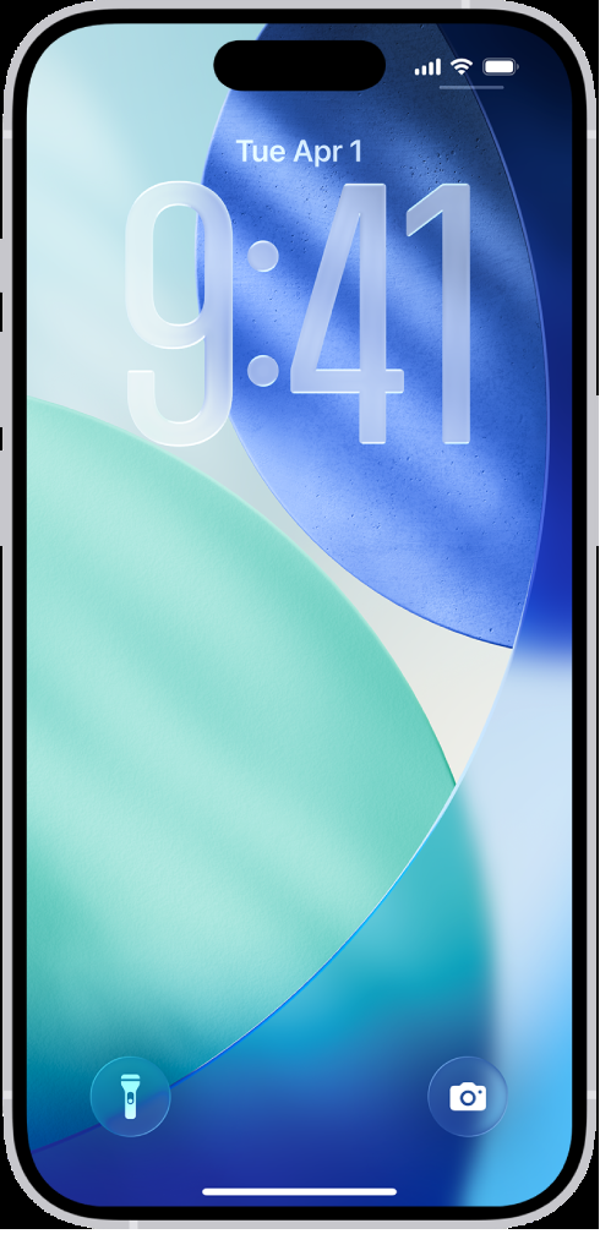

tokenizer_config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.9MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/5.44k [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/824 [00:00<?, ?B/s]

Result: intact Output: 98.3%
Expected label: intact
Probability for each option: {'damaged': 0.01691491326672651, 'intact': 0.9830850867332734}
Elapsed time: 14.649 seconds


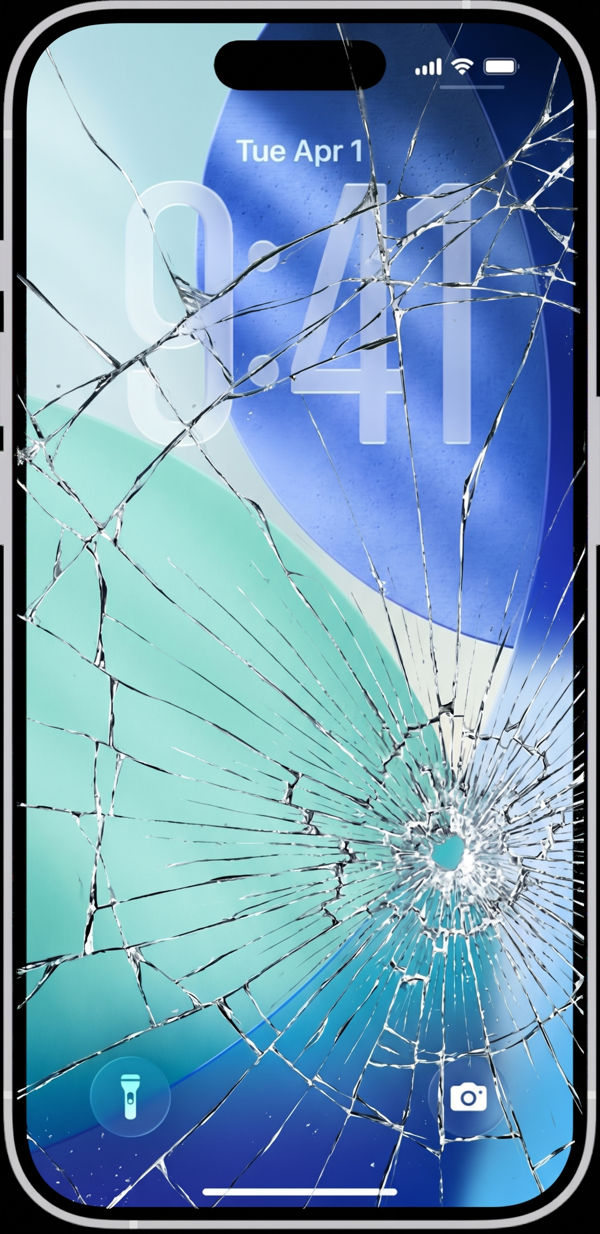

Result: damaged Output: 98.1%
Expected label: damaged
Probability for each option: {'damaged': 0.9808759632491112, 'intact': 0.019124036750888904}
Elapsed time: 3.132 seconds


In [23]:
iphone_question = {
    "type": "choice",
    "instructions": "Is the iPhone screen in the photo cracked?",
    "criteria": {"damaged": "The screen is cracked", "intact": "The screen isn't cracked"},
}
for filename, expected in [("test1.png", "intact"), ("test2.jpeg", "damaged")]:
    image = Image.open(ASSETS / "images" / filename).convert("RGB")
    display(image.resize((600, round(600 * image.height / image.width))))
    result = judge(filename, None, iphone_question, expected, images=[image])

In [24]:
examples = {
    "texts": [
        {
            "id": "text_off",
            "text": "I'm under the weather today.",
            "expected": "off"
        },
        {
            "id": "text_off",
            "text": "I'm sick today.",
            "expected": "off"
        },
        {
            "id": "text_other",
            "text": "Today is my birthday.",
            "expected": "other"
        },
        {
            "id": "text_on",
            "text": "I have to finish PR #100 today.",
            "expected": "on"
        }
    ]
}

In [25]:
text_question = {
    "type": "choice",
    "instructions": "What is the intention?",
    "criteria": {"off": "need to take an off", "on": "need to work", "other": "unknown"},
}

for case in examples["texts"]:
    print(r"input:", case["text"])
    result = judge(case["id"], case["text"], text_question, case["expected"])
    print('\n')

input: I'm under the weather today.
Result: off Output: 80.2%
Expected label: off
Probability for each option: {'off': 0.8021511087320908, 'on': 0.01886478591327724, 'other': 0.17898410535463197}
Elapsed time: 0.139 seconds


input: I'm sick today.
Result: off Output: 86.8%
Expected label: off
Probability for each option: {'off': 0.8676479164413673, 'on': 0.014928707037383408, 'other': 0.11742337652124932}
Elapsed time: 0.142 seconds


input: Today is my birthday.
Result: other Output: 68.6%
Expected label: other
Probability for each option: {'off': 0.28588674057399815, 'on': 0.02830662059025655, 'other': 0.6858066388357453}
Elapsed time: 0.141 seconds


input: I have to finish PR #100 today.
Result: on Output: 88.8%
Expected label: on
Probability for each option: {'off': 0.01842940302813921, 'on': 0.8879783657898944, 'other': 0.09359223118196638}
Elapsed time: 0.142 seconds


